<a href="https://colab.research.google.com/github/giraseniraj21-cyber/ML/blob/main/Practical_05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*   Student Name : Girase Niraj Jaypalsing
*   Div : A
*   Practical Batch : A2
*   Roll No.: 41
*   Date:
*   Practical No.: 05
*   Practical Name : Train a linar andkernel (RBF, polynomial) SVM. Tune C and gamma hyperparameters.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import seaborn as sns
from sklearn.svm import SVC

In [6]:
df = pd.read_csv("Non_linear_SVM_Dataset.csv")
df

,X1,X2,Y
0,0.830858,-0.334342,1.0
1,0.991710,0.879000,0.0
2,1.107245,-0.470344,1.0
3,-0.140899,1.033148,0.0
4,0.405592,1.328529,0.0
...,...,...,...
495,0.265123,1.023197,0.0
496,0.193576,-0.011663,1.0
497,0.345548,-0.128434,1.0
498,1.403890,-0.466993,1.0


In [7]:
Y = df["Y"]   #Output
X = df.drop(columns='Y') #Input
X.head()

,X1,X2
0,0.830858,-0.334342
1,0.991710,0.879000
2,1.107245,-0.470344
3,-0.140899,1.033148
4,0.405592,1.328529


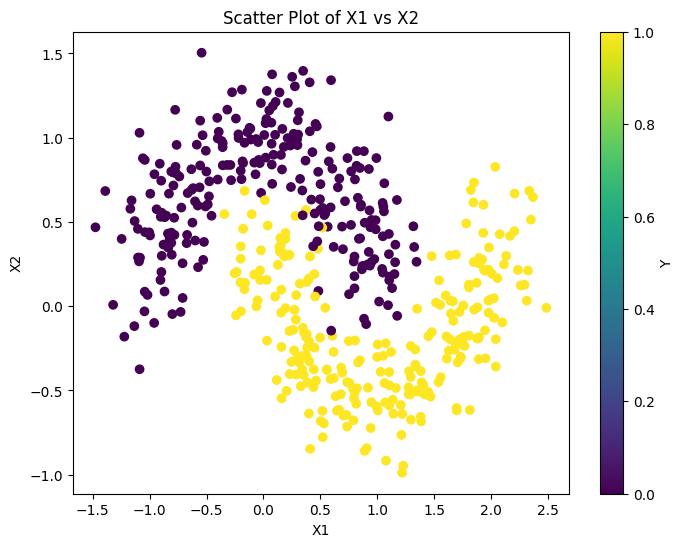

In [8]:
# Assuming X1 and X2 are the first two columns of X
plt.figure(figsize=(8, 6))
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=Y, cmap='viridis') #Use Y for color mapping
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Scatter Plot of X1 vs X2")
plt.colorbar(label="Y") # Show colorbar to represent values in Y
plt.show()

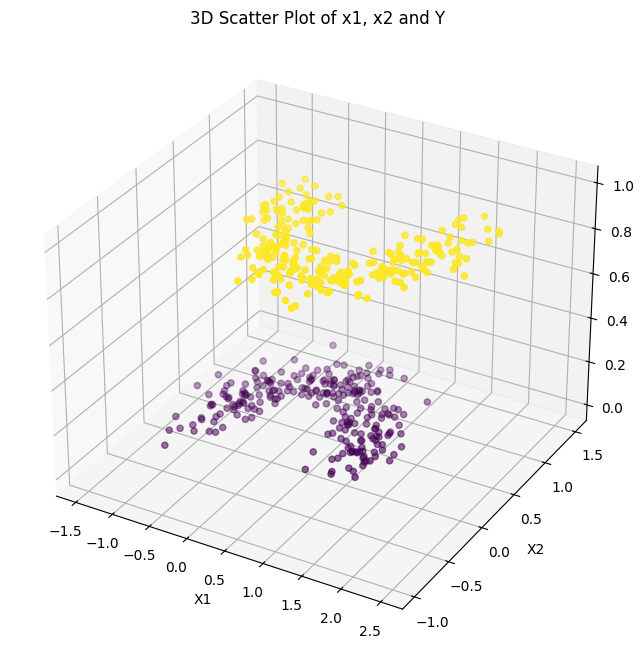

In [10]:
from mpl_toolkits.mplot3d import Axes3D
#mpl_tooljits.mplot3d is a toolkit that adds 3D plotting capabilities to Matplotlib.
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(X['X1'], X['X2'], Y, c=Y, cmap='viridis')

ax.set_xlabel('X1')
ax.set_ylabel('X2')
ax.set_zlabel('Y')
ax.set_title('3D Scatter Plot of x1, x2 and Y')
plt.show()

In [11]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.3, random_state=42)
# Test data = 30%, Training data = 70%

In [12]:
#Linear classifier
from sklearn.svm import SVC
linear_svm = SVC(kernel='linear')
linear_svm.fit(X_train, y_train)

SVC(kernel='linear')

In [13]:
from sklearn.metrics import accuracy_score

y_pred_linear = linear_svm.predict(X_test)
print("Linear SVM Accuracy:",
      accuracy_score(y_test, y_pred_linear))

Linear SVM Accuracy: 0.8666666666666667


In [14]:
# RBF SVM
rbf_svm = SVC(kernel='rbf')
rbf_svm.fit(X_train, y_train)
y_pred_rbf = rbf_svm.predict(X_test)

print("RBF SVM Accuracy:",
      accuracy_score(y_test, y_pred_rbf))

RBF SVM Accuracy: 0.98


In [15]:
# Polunomial SVM
poly_svm = SVC(kernel='poly', C=10, degree=2)

poly_svm.fit(X_train, y_train)
y_pred_poly = poly_svm.predict(X_test)

print("Polynomial SVM Accuracy:",
      accuracy_score(y_test, y_pred_poly))

Polynomial SVM Accuracy: 0.7866666666666666


In [17]:
# Hyperparameter tuning
from sklearn.model_selection import GridSearchCV

param_grid = {'C': [0.1, 1, 10, 100],
              'gamma': ['scale', 0.01, 0.1, 1]}

grid = GridSearchCV(SVC(kernel='rbf'),
                    param_grid, cv=5, scoring='accuracy')
grid.fit(X_train, y_train)
print("\nBest Parameters:")
print(grid.best_params_)


Best Parameters:
{'C': 1, 'gamma': 'scale'}


In [18]:
# Best model
from sklearn.metrics import classification_report
best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

print("\nTuned RBF SVM Accuracy:",
      accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Tuned RBF SVM Accuracy: 0.98

Classification Report:
              precision    recall  f1-score   support

         0.0       0.96      1.00      0.98        75
         1.0       1.00      0.96      0.98        75

    accuracy                           0.98       150
   macro avg       0.98      0.98      0.98       150
weighted avg       0.98      0.98      0.98       150

